In [7]:
import pandas as pd
import numpy as np

# ============================================================
# REAL ESTATE RWA UNDERWRITING & TOKENIZATION SCREENING
# ============================================================
#
# PURPOSE:
# This proof-of-concept combines:
# - Real estate financial analysis
# - Geography / regional planning concepts
# - Geospatial risk variables
# - Risk-adjusted valuation
# - Tokenization modelling
# - RWA screening logic
#
# IMPORTANT:
# All property values, rental figures, coordinates and risk
# scores used here are synthetic/illustrative data created
# for research and technical demonstration purposes.
#
# This notebook does NOT perform:
# - Legal title verification
# - Regulatory approval
# - Property certification
# - Actual blockchain token issuance
# - Investment recommendation
# ============================================================


# ============================================================
# 1. BUILD SYNTHETIC PROPERTY DATASET
# ============================================================

prop_ids = [
    "PROP-001",
    "PROP-002",
    "PROP-003",
    "PROP-004",
    "PROP-005"
]

locations = [
    "Airport Residential, Accra",
    "Cape Coast (Near UCC)",
    "Kumasi Asokwa",
    "East Legon, Accra",
    "Elmina Coastline"
]

market_values = [
    5_000_000,
    1_200_000,
    2_500_000,
    4_800_000,
    950_000
]

annual_rentals = [
    350_000,
    84_000,
    180_000,
    320_000,
    76_000
]

# Prototype risk score:
# 1 = lower risk
# 5 = higher risk
risk_scores = [
    1,
    2,
    1,
    2,
    5
]

# Geographic coordinates
latitudes = [
    5.606,
    5.114,
    6.674,
    5.632,
    5.085
]

longitudes = [
    -0.168,
    -1.282,
    -1.602,
    -0.151,
    -1.348
]


# ============================================================
# 2. CREATE DATAFRAME
# ============================================================

raw_listings = pd.DataFrame({
    "Property_ID": prop_ids,
    "Location": locations,
    "Market_Value_GHS": market_values,
    "Annual_Rental_Income_GHS": annual_rentals,
    "Zoning_Risk_Score": risk_scores,
    "Latitude": latitudes,
    "Longitude": longitudes
})


# ============================================================
# 3. BASIC DATA VALIDATION
# ============================================================

required_columns = [
    "Property_ID",
    "Location",
    "Market_Value_GHS",
    "Annual_Rental_Income_GHS",
    "Zoning_Risk_Score",
    "Latitude",
    "Longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in raw_listings.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

if (raw_listings["Market_Value_GHS"] <= 0).any():
    raise ValueError(
        "Market values must be greater than zero."
    )

if (raw_listings["Annual_Rental_Income_GHS"] < 0).any():
    raise ValueError(
        "Annual rental income cannot be negative."
    )

if not raw_listings["Zoning_Risk_Score"].between(1, 5).all():
    raise ValueError(
        "Zoning_Risk_Score must be between 1 and 5."
    )


# ============================================================
# 4. MODEL PARAMETERS
# ============================================================

# Assets with a score >= 4 fail the prototype screening rule.
HIGH_RISK_THRESHOLD = 4

# Illustrative modelling assumption:
# high-risk properties receive a 20% valuation haircut.
RISK_HAIRCUT_PCT = 20

# Theoretical token denomination for this prototype.
TOKEN_PRICE_GHS = 100


# ============================================================
# 5. RWA UNDERWRITING & SCREENING FUNCTION
# ============================================================

def process_rwa_pipeline(df):
    """
    Processes property financial metrics and performs
    prototype RWA screening.

    IMPORTANT:
    - Risk scores are illustrative.
    - The 20% haircut is a modelling assumption.
    - Token quantities are theoretical/modelled values.
    - Screening results are NOT legal or regulatory approvals.
    """

    result = df.copy()

    # --------------------------------------------------------
    # A. GROSS RENTAL YIELD
    # --------------------------------------------------------

    result["Gross_Yield_Pct"] = (
        result["Annual_Rental_Income_GHS"]
        / result["Market_Value_GHS"]
    ) * 100


    # --------------------------------------------------------
    # B. RISK ADJUSTMENT
    # --------------------------------------------------------

    result["Risk_Adjustment_Pct"] = np.where(
        result["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
        RISK_HAIRCUT_PCT,
        0
    )


    # --------------------------------------------------------
    # C. RISK-ADJUSTED PROPERTY VALUE
    # --------------------------------------------------------

    result["Risk_Adjusted_Value_GHS"] = (
        result["Market_Value_GHS"]
        * (
            1
            - result["Risk_Adjustment_Pct"] / 100
        )
    )


    # --------------------------------------------------------
    # D. MODELLED TOKEN QUANTITY
    # --------------------------------------------------------
    #
    # This is a theoretical quantity based on the modelled
    # property value and token denomination.
    #
    # It does NOT represent actual blockchain tokens.
    # --------------------------------------------------------

    result["Modelled_Token_Quantity"] = (
        result["Risk_Adjusted_Value_GHS"]
        / TOKEN_PRICE_GHS
    ).astype(int)


    # --------------------------------------------------------
    # E. RWA SCREENING STATUS
    # --------------------------------------------------------

    result["RWA_Screening_Status"] = np.where(
        result["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
        "REJECTED - HIGH RISK",
        "ELIGIBLE FOR FURTHER TOKENIZATION REVIEW"
    )


    # --------------------------------------------------------
    # F. ELIGIBLE TOKEN QUANTITY
    # --------------------------------------------------------
    #
    # Rejected assets receive zero eligible token quantity.
    # --------------------------------------------------------

    result["Eligible_Token_Quantity"] = np.where(
        result["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
        0,
        result["Modelled_Token_Quantity"]
    ).astype(int)


    # --------------------------------------------------------
    # G. SCREENING REASON
    # --------------------------------------------------------

    result["Screening_Reason"] = np.where(
        result["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
        "Failed prototype high-risk screening threshold",
        "Passed prototype risk screening"
    )

    return result


# ============================================================
# 6. RUN THE PIPELINE
# ============================================================

processed_rwa = process_rwa_pipeline(raw_listings)

# ============================================================
# 7. FORMAT DATASET FOR EXPORT
# ============================================================

export_df = processed_rwa.copy()

# Round percentage values for clean reporting
export_df["Gross_Yield_Pct"] = (
    export_df["Gross_Yield_Pct"].round(2)
)

export_df["Risk_Adjustment_Pct"] = (
    export_df["Risk_Adjustment_Pct"].round(2)
)

# Store valuation figures as whole GHS amounts
export_df["Market_Value_GHS"] = (
    export_df["Market_Value_GHS"].round(0).astype(int)
)

export_df["Risk_Adjusted_Value_GHS"] = (
    export_df["Risk_Adjusted_Value_GHS"].round(0).astype(int)
)

# Ensure token quantities are integers
export_df["Modelled_Token_Quantity"] = (
    export_df["Modelled_Token_Quantity"].astype(int)
)

export_df["Eligible_Token_Quantity"] = (
    export_df["Eligible_Token_Quantity"].astype(int)
)


# ============================================================
# 8. SAVE CLEAN PROCESSED DATASET
# ============================================================

export_df.to_csv(
    "rwa_tokenized_portfolio.csv",
    index=False
)


# ============================================================
# 8. PREPARE PORTFOLIO SCREENING MATRIX
# ============================================================

display_columns = [
    "Property_ID",
    "Location",
    "Market_Value_GHS",
    "Gross_Yield_Pct",
    "Zoning_Risk_Score",
    "Risk_Adjustment_Pct",
    "Risk_Adjusted_Value_GHS",
    "Modelled_Token_Quantity",
    "Eligible_Token_Quantity",
    "RWA_Screening_Status",
    "Screening_Reason"
]

display_df = processed_rwa[display_columns].copy()


# ============================================================
# 9. FORMAT RESULTS FOR PRESENTATION
# ============================================================

display_df["Gross_Yield_Pct"] = (
    display_df["Gross_Yield_Pct"].round(2)
)

display_df["Market_Value_GHS"] = (
    display_df["Market_Value_GHS"].astype(int)
)

display_df["Risk_Adjusted_Value_GHS"] = (
    display_df["Risk_Adjusted_Value_GHS"].astype(int)
)


# ============================================================
# 10. DISPLAY FINAL RWA SCREENING MATRIX
# ============================================================

display_df

,Property_ID,Location,Market_Value_GHS,Gross_Yield_Pct,Zoning_Risk_Score,Risk_Adjustment_Pct,Risk_Adjusted_Value_GHS,Modelled_Token_Quantity,Eligible_Token_Quantity,RWA_Screening_Status,Screening_Reason
0,PROP-001,"Airport Residential, Accra",5000000,7.00,1,0,5000000,50000,50000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,Passed prototype risk screening
1,PROP-002,Cape Coast (Near UCC),1200000,7.00,2,0,1200000,12000,12000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,Passed prototype risk screening
2,PROP-003,Kumasi Asokwa,2500000,7.20,1,0,2500000,25000,25000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,Passed prototype risk screening
3,PROP-004,"East Legon, Accra",4800000,6.67,2,0,4800000,48000,48000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,Passed prototype risk screening
4,PROP-005,Elmina Coastline,950000,8.00,5,20,760000,7600,0,REJECTED - HIGH RISK,Failed prototype high-risk screening threshold


In [1]:
%pip install geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

print("GeoPandas version:", gpd.__version__)
print("GIS libraries imported successfully.")

GeoPandas version: 1.1.4
GIS libraries imported successfully.


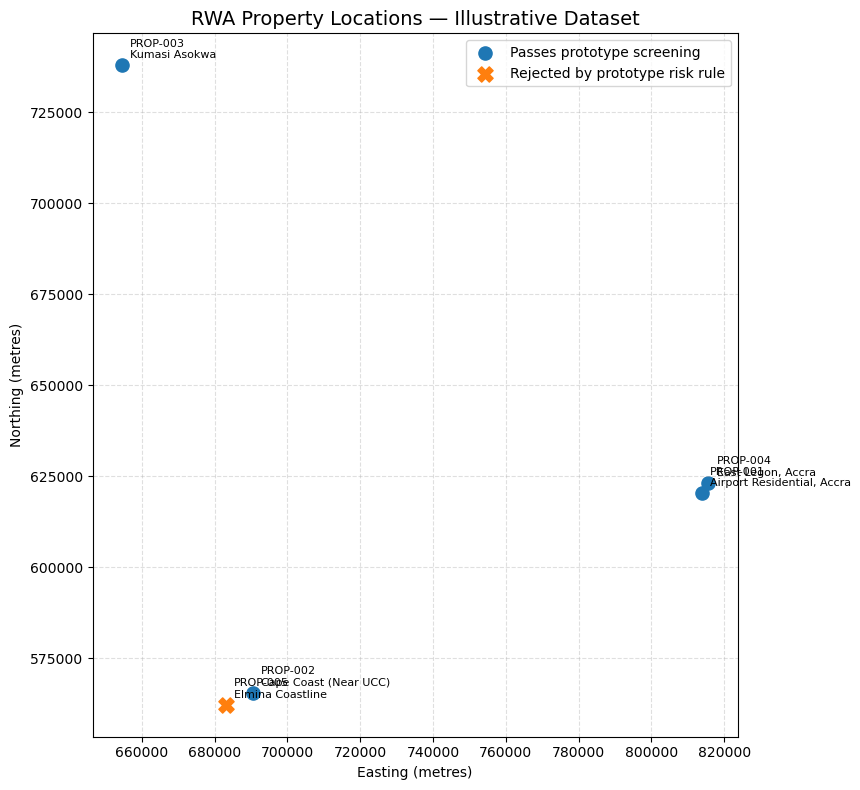

GIS property map created successfully.
Saved to: outputs/rwa_property_locations.png


In [9]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

# ============================================================
# RWA GIS MODULE: PROPERTY LOCATION MAP
# ============================================================
# This module plots the illustrative property coordinates.
# It does not independently verify property locations or
# establish actual environmental, zoning, or legal risk.
# ============================================================

# Use the processed dataset created by the main pipeline.
if "processed_rwa" in globals():
    gis_source = processed_rwa.copy()
elif "raw_listings" in globals():
    gis_source = raw_listings.copy()
else:
    raise ValueError(
        "Run the main RWA pipeline cell first."
    )

# Verify that the required fields exist.
required_fields = [
    "Property_ID",
    "Location",
    "Latitude",
    "Longitude",
    "Zoning_Risk_Score"
]

missing_fields = [
    field for field in required_fields
    if field not in gis_source.columns
]

if missing_fields:
    raise ValueError(
        f"Missing required fields: {missing_fields}"
    )

# Ensure coordinates are numeric.
gis_source["Latitude"] = pd.to_numeric(
    gis_source["Latitude"], errors="raise"
)

gis_source["Longitude"] = pd.to_numeric(
    gis_source["Longitude"], errors="raise"
)

# Convert the property table into a geographic dataset.
property_gdf = gpd.GeoDataFrame(
    gis_source,
    geometry=gpd.points_from_xy(
        gis_source["Longitude"],
        gis_source["Latitude"]
    ),
    crs="EPSG:4326"
)

# Project the points into metres for mapping.
property_map = property_gdf.to_crs(epsg=32630)

# Separate properties using the prototype screening threshold.
eligible = property_map[
    property_map["Zoning_Risk_Score"] < HIGH_RISK_THRESHOLD
]

rejected = property_map[
    property_map["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD
]

# Create the map.
fig, ax = plt.subplots(figsize=(11, 8))

if not eligible.empty:
    eligible.plot(
        ax=ax,
        marker="o",
        markersize=90,
        label="Passes prototype screening"
    )

if not rejected.empty:
    rejected.plot(
        ax=ax,
        marker="X",
        markersize=120,
        label="Rejected by prototype risk rule"
    )

# Add property identifiers and locations.
for _, row in property_map.iterrows():
    ax.annotate(
        f"{row['Property_ID']}\n{row['Location']}",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "RWA Property Locations — Illustrative Dataset",
    fontsize=14
)
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()

# Save the map for the GitHub portfolio.
os.makedirs("outputs", exist_ok=True)

fig.savefig(
    "outputs/rwa_property_locations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("GIS property map created successfully.")
print("Saved to: outputs/rwa_property_locations.png")

In [2]:
%pip install deafrica-tools


  Using cached deafrica_tools-2.5.21-py3-none-any.whl.metadata (18 kB)
  Using cached dask_ml-2025.1.0-py3-none-any.whl.metadata (6.0 kB)
  Using cached dask_gateway-2026.3.0-py3-none-any.whl.metadata (3.1 kB)
  Using cached datacube-1.9.22-py3-none-any.whl.metadata (7.4 kB)
  Using cached eo_tides-0.10.4-py3-none-any.whl.metadata (9.8 kB)
  Using cached fiona-1.10.1-cp312-cp312-win_amd64.whl.metadata (58 kB)
  Using cached gdal-3.13.3.tar.gz (940 kB)
  Installing build dependencies: started
  Installing build dependencies: still running...
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached geojson-3.3.0-py3-none-any.whl.metadata (16 kB)
  Using cached geopy-2.5.0-py3-none-any.whl.metadata (7.1 kB)
  Using cached hdstats-0.2.1.tar.gz (5

  error: subprocess-exited-with-error
  
  exit code: 1
  
  [126 lines of output]
  C:\Users\User\AppData\Local\Temp\pip-build-env-qcv06a24\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsWarning: `license` overwritten by `pyproject.toml`
    corresp(dist, value, root_dir)
  C:\Users\User\AppData\Local\Temp\pip-build-env-qcv06a24\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsWarning: `extras_require` overwritten in `pyproject.toml` (optional-dependencies)
    corresp(dist, value, root_dir)
  Using numpy 2.5.4
  running bdist_wheel
  running build
  running build_py
  creating build\lib.win-amd64-cpython-312\osgeo
  copying osgeo\gdal.py -> build\lib.win-amd64-cpython-312\osgeo
  copying osgeo\gdalconst.py -> build\lib.win-amd64-cpython-312\osgeo
  copying osgeo\gdalnumeric.py -> build\lib.win-amd64-cpython-312\osgeo
  copying osgeo\gdal_array.py -> build\lib.win-amd64-cpython-312\osgeo
  copying osgeo\gdal_fsspec.py

In [11]:
import requests
import geopandas as gpd
from IPython.display import display

# Digital Earth Africa Coastlines WFS
WFS_URL = "https://geoserver.digitalearth.africa/geoserver/wfs"

# Cape Coast–Elmina study area.
# WFS 1.1.0 with EPSG:4326 uses latitude/longitude
# axis ordering in this bounding-box representation.
params = {
    "service": "WFS",
    "version": "1.1.0",
    "request": "GetFeature",
    "typeName": "coastlines_v0.4.4_rates_of_change",
    "outputFormat": "application/json",
    "maxFeatures": 1000,
    "bbox": "4.98,-1.45,5.22,-1.18,urn:ogc:def:crs:EPSG:4326"
}

print("Requesting coastal-change data...")

try:
    response = requests.get(
        WFS_URL,
        params=params,
        timeout=90
    )

    print("HTTP status:", response.status_code)

    if not response.ok:
        print("Server response:")
        print(response.text[:3000])

    else:
        data = response.json()

        if "features" not in data:
            print("The response did not contain a GeoJSON feature collection.")
            print(str(data)[:3000])

        else:
            coast_change = gpd.GeoDataFrame.from_features(
                data["features"],
                crs="EPSG:4326"
            )

            print("Coastal data retrieved successfully.")
            print("Features retrieved:", len(coast_change))
            print("Available columns:", coast_change.columns.tolist())

            display(coast_change.head(10))

except requests.RequestException as exc:
    print("Network request failed:", str(exc))

except ValueError as exc:
    print("Could not parse the server response:", str(exc))

Requesting coastal-change data...
HTTP status: 200
Network request failed: Expecting value: line 1 column 1 (char 0)


In [13]:
print("Response content type:")
print(response.headers.get("Content-Type"))

print("\nResponse body (first 2,000 characters):")
print(response.text[:2000] if response.text else "[Empty response]")

Response content type:
application/xml

Response body (first 2,000 characters):
<?xml version="1.0" encoding="UTF-8"?><ows:ExceptionReport xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:ows="http://www.opengis.net/ows" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" version="1.0.0" xsi:schemaLocation="http://www.opengis.net/ows https://geoserver.digitalearth.africa/geoserver/schemas/ows/1.0.0/owsExceptionReport.xsd">
  <ows:Exception exceptionCode="InvalidParameterValue" locator="typeName">
    <ows:ExceptionText>Feature type :coastlines_v0.4.4_rates_of_change unknown</ows:ExceptionText>
  </ows:Exception>
</ows:ExceptionReport>



In [15]:
import requests
import xml.etree.ElementTree as ET

WFS_URL = "https://geoserver.digitalearth.africa/geoserver/wfs"

params = {
    "service": "WFS",
    "version": "1.1.0",
    "request": "GetCapabilities"
}

print("Checking available Digital Earth Africa layers...")

try:
    r = requests.get(WFS_URL, params=params, timeout=60)
    print("HTTP status:", r.status_code)
    r.raise_for_status()

    root = ET.fromstring(r.content)

    layer_names = []

    for feature_type in root.iter():
        if feature_type.tag.split("}")[-1] == "FeatureType":
            for child in feature_type:
                if (
                    child.tag.split("}")[-1] == "Name"
                    and child.text
                ):
                    layer_names.append(child.text.strip())

    coastal_layers = [
        name for name in layer_names
        if "coast" in name.lower()
    ]

    if coastal_layers:
        print("\nAvailable coastal layers:")
        for name in coastal_layers:
            print("-", name)
    else:
        print("\nNo coastal layers found. Available layers:")
        for name in layer_names[:50]:
            print("-", name)

except Exception as e:
    print("Request failed:", type(e).__name__, str(e))

Checking available Digital Earth Africa layers...
HTTP status: 200

Available coastal layers:
- coastlines:coastlines_v0_3_0
- coastlines:coastlines_v0_3_0_hotspots_zoom_1
- coastlines:coastlines_v0_3_0_hotspots_zoom_2
- coastlines:coastlines_v0_3_0_hotspots_zoom_3
- coastlines:coastlines_v0_3_0_rates_of_change
- coastlines:coastlines_v0_4_0_hotspots_zoom_1
- coastlines:coastlines_v0_4_0_hotspots_zoom_2
- coastlines:coastlines_v0_4_0_hotspots_zoom_3
- coastlines:coastlines_v0_4_0_rates_of_change
- coastlines:coastlines_v0_4_0_shorelines_annual
- coastlines:coastlines_v0_4_1_hotspots_zoom_1
- coastlines:coastlines_v0_4_1_hotspots_zoom_2
- coastlines:coastlines_v0_4_1_hotspots_zoom_3
- coastlines:coastlines_v0_4_1_rates_of_change
- coastlines:coastlines_v0_4_1_shorelines_annual
- coastlines:coastlines_v0_4_2_hotspots_zoom_1
- coastlines:coastlines_v0_4_2_hotspots_zoom_2
- coastlines:coastlines_v0_4_2_hotspots_zoom_3
- coastlines:coastlines_v0_4_2_rates_of_change
- coastlines:coastlines_v

In [21]:
# ============================================================
# RWA GIS: RETRIEVE DIGITAL EARTH AFRICA COASTAL-CHANGE DATA
# ============================================================

import requests
import geopandas as gpd
from IPython.display import display

WFS_URL = "https://geoserver.digitalearth.africa/geoserver/wfs"

# Cape Coast–Elmina study area.
# WFS 1.1.0 with EPSG:4326 uses latitude/longitude axis order.
bbox = "4.98,-1.45,5.22,-1.18,urn:ogc:def:crs:EPSG:4326"

params = {
    "service": "WFS",
    "version": "1.1.0",
    "request": "GetFeature",
    "typeName": "coastlines:coastlines_v0_4_4_rates_of_change",
    "outputFormat": "application/json",
    "srsName": "EPSG:4326",
    "bbox": bbox,
    "maxFeatures": 1000
}

print("Requesting coastal-change data...")

try:
    response = requests.get(
        WFS_URL,
        params=params,
        timeout=90
    )

    print("HTTP status:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))

    response.raise_for_status()

    # Confirm that the server returned JSON, not an XML exception.
    if "json" not in response.headers.get("Content-Type", "").lower():
        print("The server did not return JSON.")
        print(response.text[:2500])

    else:
        data = response.json()

        if "features" not in data:
            print("No GeoJSON feature collection was returned.")
            print(str(data)[:2500])

        else:
            coast_change = gpd.GeoDataFrame.from_features(
                data["features"],
                crs="EPSG:4326"
            )

            print("\nCoastal-data request completed.")
            print("Features retrieved:", len(coast_change))
            print("Available fields:")
            print(coast_change.columns.tolist())

            if not coast_change.empty:
                display(coast_change.head(10))
            else:
                print(
                    "No features were found in this bounding box. "
                    "We will check the spatial extent next."
                )

except requests.RequestException as exc:
    print("Request failed:", type(exc).__name__, str(exc))

Requesting coastal-change data...
HTTP status: 200
Content type: application/json;charset=UTF-8

Coastal-data request completed.
Features retrieved: 1000
Available fields:
['geometry', 'uid', 'rate_time', 'sig_time', 'se_time', 'outl_time', 'dist_2000', 'dist_2001', 'dist_2002', 'dist_2003', 'dist_2004', 'dist_2005', 'dist_2006', 'dist_2007', 'dist_2008', 'dist_2009', 'dist_2010', 'dist_2011', 'dist_2012', 'dist_2013', 'dist_2014', 'dist_2015', 'dist_2016', 'dist_2017', 'dist_2018', 'dist_2019', 'dist_2020', 'dist_2021', 'dist_2022', 'dist_2023', 'dist_2024', 'dist_2025', 'angle_mean', 'angle_std', 'valid_obs', 'valid_span', 'sce', 'nsm', 'max_year', 'min_year', 'certainty', 'country', 'wms_abs', 'wms_conf', 'wms_grew', 'wms_retr', 'wms_sig', 'wms_good']


,geometry,uid,rate_time,sig_time,se_time,outl_time,dist_2000,dist_2001,dist_2002,dist_2003,...,max_year,min_year,certainty,country,wms_abs,wms_conf,wms_grew,wms_retr,wms_sig,wms_good
0,POINT (-1.19928 5.12792),None,0.25,0.000,0.05,,-4.69,-5.07,-4.17,-2.78,...,2020,2001,good,Ghana,0.25,1,1,0,1,1
1,POINT (-1.19914 5.12815),None,0.28,0.009,0.10,,-6.88,-7.11,-6.77,-6.01,...,2023,2001,good,Ghana,0.28,1,1,0,1,1
2,POINT (-1.19895 5.12833),None,0.25,0.016,0.10,,-5.13,-6.90,-7.37,-7.36,...,2004,2002,good,Ghana,0.25,1,1,0,0,1
3,POINT (-1.19873 5.12848),None,0.33,0.001,0.09,,-3.23,-5.71,-6.81,-6.75,...,2020,2002,good,Ghana,0.33,1,1,0,1,1
4,POINT (-1.19852 5.12866),None,0.21,0.008,0.07,2003,-0.96,-1.45,-1.82,NaN,...,2023,2006,good,Ghana,0.21,1,1,0,1,1
5,POINT (-1.19836 5.12888),None,0.16,0.056,0.08,2003,1.52,1.37,0.49,NaN,...,2018,2006,good,Ghana,0.16,1,1,0,0,1
6,POINT (-1.19822 5.12911),None,0.06,0.451,0.08,2003,2.33,2.73,2.81,NaN,...,2008,2005,good,Ghana,0.06,1,1,0,0,1
7,POINT (-1.19809 5.12935),None,0.01,0.949,0.12,2003,1.80,2.85,4.35,NaN,...,2010,2024,good,Ghana,0.01,1,1,0,0,1
8,POINT (-1.19793 5.12956),None,0.14,0.070,0.07,2003,0.25,-0.52,0.09,NaN,...,2023,2005,good,Ghana,0.14,1,1,0,0,1
9,POINT (-1.19775 5.12977),None,0.19,0.013,0.07,2003,-1.44,-1.30,-1.76,NaN,...,2023,2012,good,Ghana,0.19,1,1,0,0,1


In [5]:
import requests
import geopandas as gpd
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

WFS_URL = "https://geoserver.digitalearth.africa/geoserver/wfs"

# Focused Cape Coast–Elmina study area.
# EPSG:4326 axis order for this WFS request: latitude, longitude.
bbox = "5.04,-1.40,5.15,-1.25,urn:ogc:def:crs:EPSG:4326"

params = {
    "service": "WFS",
    "version": "1.1.0",
    "request": "GetFeature",
    "typeName": "coastlines:coastlines_v0_4_4_rates_of_change",
    "outputFormat": "application/json",
    "srsName": "EPSG:4326",
    "bbox": bbox,
    "maxFeatures": 1000
}

# Retry a limited number of times for temporary server failures.
session = requests.Session()
retry_strategy = Retry(
    total=2,
    connect=2,
    read=0,
    status=2,
    backoff_factor=1,
    status_forcelist=[502, 503, 504],
    allowed_methods=["GET"]
)
session.mount("https://", HTTPAdapter(max_retries=retry_strategy))

print("Requesting coastal observations for the smaller area...")

try:
    response = session.get(
        WFS_URL,
        params=params,
        timeout=(20, 60)
    )

    print("HTTP status:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))
    response.raise_for_status()

    if "json" not in response.headers.get("Content-Type", "").lower():
        print("Unexpected server response:")
        print(response.text[:2000])
    else:
        data = response.json()
        features = data.get("features", [])

        if not features:
            print("No coastal observations returned for this area.")
        else:
            coast_change_local = gpd.GeoDataFrame.from_features(
                features,
                crs="EPSG:4326"
            )

            print("Features retrieved:", len(coast_change_local))
            print("Available fields:")
            print(coast_change_local.columns.tolist())

            display(coast_change_local.head(10))

except requests.RequestException as exc:
    print("The coastal-data request failed:", str(exc))

Requesting coastal observations for the smaller area...
HTTP status: 200
Content type: application/json;charset=UTF-8
Features retrieved: 626
Available fields:
['geometry', 'uid', 'rate_time', 'sig_time', 'se_time', 'outl_time', 'dist_2000', 'dist_2001', 'dist_2002', 'dist_2003', 'dist_2004', 'dist_2005', 'dist_2006', 'dist_2007', 'dist_2008', 'dist_2009', 'dist_2010', 'dist_2011', 'dist_2012', 'dist_2013', 'dist_2014', 'dist_2015', 'dist_2016', 'dist_2017', 'dist_2018', 'dist_2019', 'dist_2020', 'dist_2021', 'dist_2022', 'dist_2023', 'dist_2024', 'dist_2025', 'angle_mean', 'angle_std', 'valid_obs', 'valid_span', 'sce', 'nsm', 'max_year', 'min_year', 'certainty', 'country', 'wms_abs', 'wms_conf', 'wms_grew', 'wms_retr', 'wms_sig', 'wms_good']


,geometry,uid,rate_time,sig_time,se_time,outl_time,dist_2000,dist_2001,dist_2002,dist_2003,...,max_year,min_year,certainty,country,wms_abs,wms_conf,wms_grew,wms_retr,wms_sig,wms_good
0,POINT (-1.39993 5.06958),None,-0.12,0.281,0.11,,2.09,1.13,-1.11,0.94,...,2007,2013,good,Ghana,0.12,1,0,1,0,1
1,POINT (-1.39966 5.0696),None,-0.08,0.443,0.11,,4.67,-0.51,-0.24,3.04,...,2007,2013,good,Ghana,0.08,1,0,1,0,1
2,POINT (-1.39939 5.06966),None,-0.07,0.526,0.11,,5.57,-0.44,-0.43,7.33,...,2014,2013,good,Ghana,0.07,1,0,1,0,1
3,POINT (-1.39913 5.06973),None,-0.04,0.789,0.13,,1.42,-1.65,-1.68,7.41,...,2014,2013,good,Ghana,0.04,1,0,1,0,1
4,POINT (-1.39887 5.06977),None,0.04,0.693,0.11,,1.04,-3.23,-3.56,3.65,...,2019,2002,good,Ghana,0.04,1,1,0,0,1
5,POINT (-1.3986 5.06979),None,0.07,0.488,0.10,,0.06,-4.20,-5.66,2.62,...,2019,2002,good,Ghana,0.07,1,1,0,0,1
6,POINT (-1.39833 5.06981),None,0.06,0.497,0.08,,1.16,-2.72,-3.58,1.05,...,2007,2002,good,Ghana,0.06,1,1,0,0,1
7,POINT (-1.39806 5.06982),None,0.04,0.649,0.08,,1.71,-1.71,-3.00,-0.36,...,2007,2012,good,Ghana,0.04,1,1,0,0,1
8,POINT (-1.39779 5.06987),None,0.07,0.420,0.09,,-0.33,-0.55,-3.29,-0.05,...,2007,2013,good,Ghana,0.07,1,1,0,0,1
9,POINT (-1.39753 5.06995),None,0.09,0.536,0.14,,2.85,-1.63,-2.64,-1.63,...,2007,2010,good,Ghana,0.09,1,1,0,0,1


In [9]:
# ============================================================
# RWA GIS: LINK SAMPLE PROPERTIES TO COASTAL OBSERVATIONS
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
from IPython.display import display

# ------------------------------------------------------------
# 1. CHECK THAT THE COASTAL DATA IS AVAILABLE
# ------------------------------------------------------------

if "coast_change_local" not in globals():
    raise ValueError(
        "The coastal dataset is not in memory. "
        "Run the successful coastal-data download cell first."
    )

# ------------------------------------------------------------
# 2. RECREATE THE FIVE ILLUSTRATIVE PROPERTY RECORDS
# ------------------------------------------------------------
# These are the same synthetic coordinates used in the
# original RWA prototype. They are NOT verified property sites.

property_source = pd.DataFrame({
    "Property_ID": [
        "PROP-001", "PROP-002", "PROP-003",
        "PROP-004", "PROP-005"
    ],
    "Location": [
        "Airport Residential, Accra",
        "Cape Coast (Near UCC)",
        "Kumasi Asokwa",
        "East Legon, Accra",
        "Elmina Coastline"
    ],
    "Latitude": [5.606, 5.114, 6.674, 5.632, 5.085],
    "Longitude": [-0.168, -1.282, -1.602, -0.151, -1.348],
    "Market_Value_GHS": [
        5_000_000, 1_200_000, 2_500_000,
        4_800_000, 950_000
    ],
    "Zoning_Risk_Score": [1, 2, 1, 2, 5]
})

# Only the properties inside the downloaded coastal study area.
local_properties = property_source.loc[
    property_source["Longitude"].between(-1.45, -1.18)
    & property_source["Latitude"].between(4.98, 5.22)
].copy()

if local_properties.empty:
    raise ValueError(
        "No sample properties fall inside the selected coastal area."
    )

print("Properties in coastal study area:")
display(
    local_properties[["Property_ID", "Location", "Latitude", "Longitude"]]
)

# ------------------------------------------------------------
# 3. PREPARE COASTAL OBSERVATIONS
# ------------------------------------------------------------

coast_gdf = coast_change_local.copy()

if coast_gdf.crs is None:
    coast_gdf = coast_gdf.set_crs("EPSG:4326")

coast_gdf = coast_gdf.loc[
    coast_gdf.geometry.notna()
    & ~coast_gdf.geometry.is_empty
].copy()

if "country" in coast_gdf.columns:
    coast_gdf = coast_gdf.loc[
        coast_gdf["country"].eq("Ghana")
    ].copy()

if coast_gdf.empty:
    raise ValueError("No usable Ghana coastal observations were found.")

# Convert measurements to numeric values.
for column in ["rate_time", "sig_time", "se_time"]:
    if column in coast_gdf.columns:
        coast_gdf[column] = pd.to_numeric(
            coast_gdf[column], errors="coerce"
        )

# ------------------------------------------------------------
# 4. CREATE GEOGRAPHIC DATASETS
# ------------------------------------------------------------

properties_gdf = gpd.GeoDataFrame(
    local_properties,
    geometry=gpd.points_from_xy(
        local_properties["Longitude"],
        local_properties["Latitude"]
    ),
    crs="EPSG:4326"
)

coastal_fields = [
    "rate_time",
    "sig_time",
    "se_time",
    "certainty",
    "valid_obs",
    "min_year",
    "max_year",
    "geometry"
]

coastal_fields = [
    field for field in coastal_fields
    if field in coast_gdf.columns
]

# Project to UTM Zone 30N so distances are measured in metres.
properties_m = properties_gdf.to_crs("EPSG:32630")
coast_m = coast_gdf[coastal_fields].to_crs("EPSG:32630")

# ------------------------------------------------------------
# 5. FIND THE NEAREST COASTAL-CHANGE OBSERVATION
# ------------------------------------------------------------

nearest = gpd.sjoin_nearest(
    properties_m,
    coast_m,
    how="left",
    distance_col="Nearest_Observation_Distance_m"
)

nearest["Nearest_Observation_Distance_km"] = (
    nearest["Nearest_Observation_Distance_m"] / 1000
).round(3)

# Sort and retain one nearest observation per property.
nearest = nearest.sort_values(
    "Nearest_Observation_Distance_m"
).drop_duplicates("Property_ID")

if "rate_time" in nearest.columns:
    nearest["Reported_Trend"] = np.select(
        [
            nearest["rate_time"] < 0,
            nearest["rate_time"] > 0
        ],
        [
            "Retreat indicated",
            "Growth indicated"
        ],
        default="Near-zero or unavailable trend"
    )

if "sig_time" in nearest.columns:
    nearest["Significant_at_1pct"] = (
        nearest["sig_time"] < 0.01
    )

# ------------------------------------------------------------
# 6. DISPLAY AND SAVE RESULTS
# ------------------------------------------------------------

output_columns = [
    "Property_ID",
    "Location",
    "Nearest_Observation_Distance_km",
    "rate_time",
    "se_time",
    "sig_time",
    "Significant_at_1pct",
    "certainty",
    "Reported_Trend"
]

output_columns = [
    column for column in output_columns
    if column in nearest.columns
]

coastal_linkage = (
    pd.DataFrame(nearest[output_columns])
    .reset_index(drop=True)
)

display(coastal_linkage)

os.makedirs("outputs", exist_ok=True)

coastal_linkage.to_csv(
    "outputs/rwa_coastal_linkage.csv",
    index=False
)

print("\nSaved: outputs/rwa_coastal_linkage.csv")
print("Properties analysed:", len(coastal_linkage))

print(
    "\nImportant: distances are to the nearest retrieved "
    "coastal-change observation point, not necessarily the "
    "shoreline itself. The sample coordinates are illustrative, "
    "so the results are not verified property-risk assessments."
)

Properties in coastal study area:


,Property_ID,Location,Latitude,Longitude
1,PROP-002,Cape Coast (Near UCC),5.114,-1.282
4,PROP-005,Elmina Coastline,5.085,-1.348


,Property_ID,Location,Nearest_Observation_Distance_km,rate_time,se_time,sig_time,Significant_at_1pct,certainty,Reported_Trend
0,PROP-005,Elmina Coastline,0.021,0.15,0.19,0.421,False,good,Growth indicated
1,PROP-002,Cape Coast (Near UCC),1.531,-0.50,0.14,0.002,True,good,Retreat indicated



Saved: outputs/rwa_coastal_linkage.csv
Properties analysed: 2

Important: distances are to the nearest retrieved coastal-change observation point, not necessarily the shoreline itself. The sample coordinates are illustrative, so the results are not verified property-risk assessments.


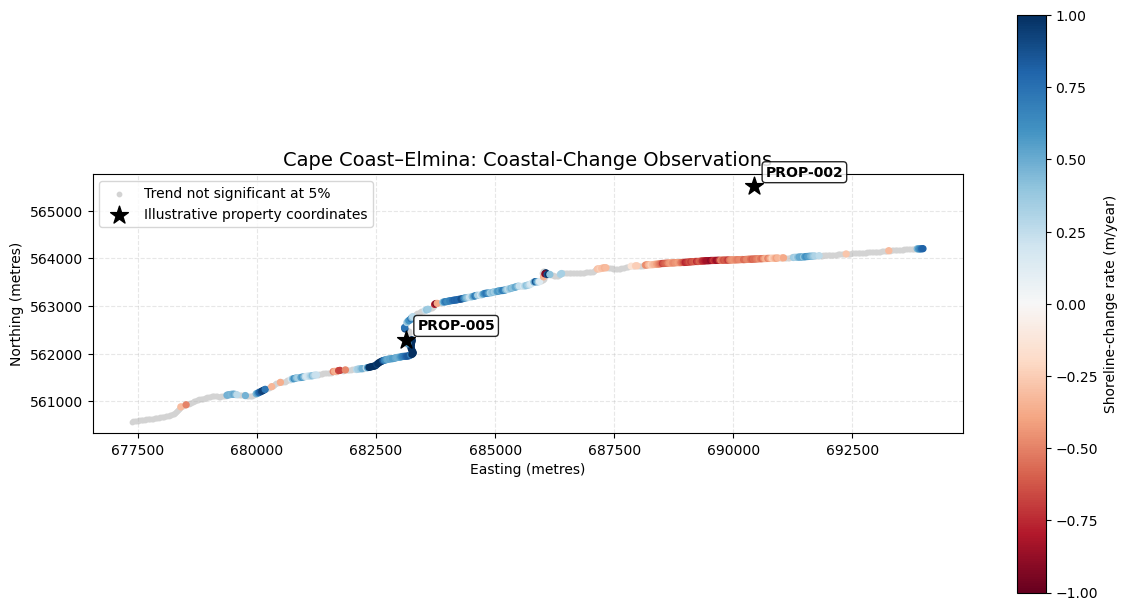

Map saved: outputs/rwa_coastal_change_map.png
Coastal observations mapped: 626
Significant at 5%: 323
Not significant at 5%: 303
Note: property coordinates are illustrative, and coastal-change observations do not by themselves establish parcel-level risk.


In [13]:
# ============================================================
# RWA GIS: COASTAL CHANGE MAP
# Digital Earth Africa Coastlines observations
# ============================================================

import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Check that the downloaded data is available
if "coast_change_local" not in globals():
    raise ValueError(
        "Run the successful coastal-data download cell first."
    )

# Prepare coastal observations
coast = coast_change_local.copy()

if coast.crs is None:
    coast = coast.set_crs("EPSG:4326")

coast = coast[
    coast.geometry.notna() & ~coast.geometry.is_empty
].copy()

if "country" in coast.columns:
    coast = coast[coast["country"].eq("Ghana")].copy()

coast["rate_time"] = pd.to_numeric(
    coast["rate_time"], errors="coerce"
)
coast["sig_time"] = pd.to_numeric(
    coast["sig_time"], errors="coerce"
)

coast = coast.dropna(subset=["rate_time", "sig_time"])

# Mark observations by statistical significance
significant = coast[coast["sig_time"] < 0.05].copy()
not_significant = coast[coast["sig_time"] >= 0.05].copy()

# Recreate the illustrative property locations
properties = pd.DataFrame({
    "Property_ID": ["PROP-002", "PROP-005"],
    "Location": ["Cape Coast (Near UCC)", "Elmina Coastline"],
    "Latitude": [5.114, 5.085],
    "Longitude": [-1.282, -1.348]
})

properties_gdf = gpd.GeoDataFrame(
    properties,
    geometry=gpd.points_from_xy(
        properties["Longitude"],
        properties["Latitude"]
    ),
    crs="EPSG:4326"
)

# Project both datasets to metres
coast_m = coast.to_crs("EPSG:32630")
significant_m = significant.to_crs("EPSG:32630")
not_significant_m = not_significant.to_crs("EPSG:32630")
properties_m = properties_gdf.to_crs("EPSG:32630")

# Draw map
fig, ax = plt.subplots(figsize=(12, 8))

# Observations without a statistically significant trend
if not not_significant_m.empty:
    not_significant_m.plot(
        ax=ax,
        color="lightgrey",
        markersize=10,
        label="Trend not significant at 5%",
        zorder=1
    )

# Observations with a statistically significant trend
if not significant_m.empty:
    significant_m.plot(
        ax=ax,
        column="rate_time",
        cmap="RdBu",
        vmin=-1,
        vmax=1,
        markersize=18,
        legend=True,
        legend_kwds={
            "label": "Shoreline-change rate (m/year)",
            "shrink": 0.75
        },
        zorder=2
    )

# Plot sample properties
properties_m.plot(
    ax=ax,
    color="black",
    marker="*",
    markersize=180,
    label="Illustrative property coordinates",
    zorder=5
)

# Add readable property labels
for _, row in properties_m.iterrows():
    ax.annotate(
        row["Property_ID"],
        (row.geometry.x, row.geometry.y),
        xytext=(8, 7),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "alpha": 0.85
        },
        zorder=6
    )

ax.set_title(
    "Cape Coast–Elmina: Coastal-Change Observations",
    fontsize=14
)
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()

# Save the map
os.makedirs("outputs", exist_ok=True)

fig.savefig(
    "outputs/rwa_coastal_change_map.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Map saved: outputs/rwa_coastal_change_map.png")
print("Coastal observations mapped:", len(coast))
print("Significant at 5%:", len(significant))
print("Not significant at 5%:", len(not_significant))

print(
    "Note: property coordinates are illustrative, and "
    "coastal-change observations do not by themselves "
    "establish parcel-level risk."
)

In [15]:
# ============================================================
# RWA GIS: QUALITY-AWARE COASTAL EVIDENCE TABLE
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
from IPython.display import display

# ------------------------------------------------------------
# 1. DEFINE THE TWO ILLUSTRATIVE COASTAL PROPERTIES
# ------------------------------------------------------------

properties = pd.DataFrame({
    "Property_ID": ["PROP-002", "PROP-005"],
    "Location": [
        "Cape Coast (Near UCC)",
        "Elmina Coastline"
    ],
    "Latitude": [5.114, 5.085],
    "Longitude": [-1.282, -1.348]
})

# ------------------------------------------------------------
# 2. CHECK THE DOWNLOADED COASTAL DATA
# ------------------------------------------------------------

if "coast_change_local" not in globals():
    raise ValueError(
        "Run the successful coastal-data download cell first."
    )

coast = coast_change_local.copy()

if coast.crs is None:
    coast = coast.set_crs("EPSG:4326")

coast = coast.loc[
    coast.geometry.notna()
    & ~coast.geometry.is_empty
].copy()

for column in ["rate_time", "sig_time", "se_time"]:
    coast[column] = pd.to_numeric(
        coast[column], errors="coerce"
    )

coast = coast.dropna(
    subset=["rate_time", "sig_time", "se_time"]
)

# ------------------------------------------------------------
# 3. CREATE SPATIAL DATASETS
# ------------------------------------------------------------

property_gdf = gpd.GeoDataFrame(
    properties,
    geometry=gpd.points_from_xy(
        properties["Longitude"],
        properties["Latitude"]
    ),
    crs="EPSG:4326"
)

# UTM Zone 30N: distances are calculated in metres.
properties_m = property_gdf.to_crs("EPSG:32630")
coast_m = coast.to_crs("EPSG:32630")

nearest = gpd.sjoin_nearest(
    properties_m,
    coast_m[
        [
            "rate_time",
            "sig_time",
            "se_time",
            "certainty",
            "valid_obs",
            "min_year",
            "max_year",
            "geometry"
        ]
    ],
    how="left",
    distance_col="Nearest_Observation_Distance_m"
)

# Keep one nearest observation per property.
nearest = (
    nearest.sort_values("Nearest_Observation_Distance_m")
    .drop_duplicates("Property_ID")
    .copy()
)

nearest["Nearest_Observation_Distance_km"] = (
    nearest["Nearest_Observation_Distance_m"] / 1000
).round(3)

# ------------------------------------------------------------
# 4. CALCULATE APPROXIMATE 95% CONFIDENCE INTERVALS
# ------------------------------------------------------------

nearest["Rate_CI95_Lower"] = (
    nearest["rate_time"] - 1.96 * nearest["se_time"]
).round(3)

nearest["Rate_CI95_Upper"] = (
    nearest["rate_time"] + 1.96 * nearest["se_time"]
).round(3)

nearest["Significant_at_1pct"] = (
    nearest["sig_time"] < 0.01
)

# ------------------------------------------------------------
# 5. CREATE EXPLICIT INTERPRETATION NOTES
# ------------------------------------------------------------

def interpret_observation(row):
    rate = row["rate_time"]
    p_value = row["sig_time"]
    distance = row["Nearest_Observation_Distance_km"]

    if p_value < 0.01 and rate < 0:
        trend = "Significant retreat trend at nearest observation"
    elif p_value < 0.01 and rate > 0:
        trend = "Significant growth trend at nearest observation"
    else:
        trend = "No statistically significant trend at 1%"

    if distance > 1:
        linkage = (
            "Nearest observation is over 1 km away; "
            "parcel-level relationship needs validation"
        )
    else:
        linkage = (
            "Observation is nearby; verify actual parcel "
            "and shoreline geometry before interpretation"
        )

    return pd.Series({
        "Coastal_Trend_Interpretation": trend,
        "Spatial_Linkage_Note": linkage
    })

interpretations = nearest.apply(
    interpret_observation,
    axis=1
)

nearest = pd.concat(
    [nearest, interpretations],
    axis=1
)

# ------------------------------------------------------------
# 6. PREPARE THE EVIDENCE TABLE
# ------------------------------------------------------------

columns = [
    "Property_ID",
    "Location",
    "Nearest_Observation_Distance_km",
    "rate_time",
    "se_time",
    "Rate_CI95_Lower",
    "Rate_CI95_Upper",
    "sig_time",
    "Significant_at_1pct",
    "certainty",
    "valid_obs",
    "Coastal_Trend_Interpretation",
    "Spatial_Linkage_Note"
]

evidence_table = pd.DataFrame(nearest[columns])

display(evidence_table)

# ------------------------------------------------------------
# 7. SAVE THE RESULTS
# ------------------------------------------------------------

os.makedirs("outputs", exist_ok=True)

evidence_table.to_csv(
    "outputs/rwa_coastal_evidence_table.csv",
    index=False
)

print("\nSaved: outputs/rwa_coastal_evidence_table.csv")
print("Properties analysed:", len(evidence_table))

print(
    "\nDisclaimer: coordinates are illustrative. "
    "These observations are not property-level risk ratings."
)

,Property_ID,Location,Nearest_Observation_Distance_km,rate_time,se_time,Rate_CI95_Lower,Rate_CI95_Upper,sig_time,Significant_at_1pct,certainty,valid_obs,Coastal_Trend_Interpretation,Spatial_Linkage_Note
1,PROP-005,Elmina Coastline,0.021,0.15,0.19,-0.222,0.522,0.421,False,good,21,No statistically significant trend at 1%,Observation is nearby; verify actual parcel an...
0,PROP-002,Cape Coast (Near UCC),1.531,-0.50,0.14,-0.774,-0.226,0.002,True,good,26,Significant retreat trend at nearest observation,Nearest observation is over 1 km away; parcel-...



Saved: outputs/rwa_coastal_evidence_table.csv
Properties analysed: 2

Disclaimer: coordinates are illustrative. These observations are not property-level risk ratings.


In [19]:
# ============================================================
# RWA: INTEGRATED PROPERTY PORTFOLIO + COASTAL EVIDENCE
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. REBUILD THE ILLUSTRATIVE PROPERTY PORTFOLIO
# ------------------------------------------------------------

portfolio = pd.DataFrame({
    "Property_ID": [
        "PROP-001", "PROP-002", "PROP-003",
        "PROP-004", "PROP-005"
    ],
    "Location": [
        "Airport Residential, Accra",
        "Cape Coast (Near UCC)",
        "Kumasi Asokwa",
        "East Legon, Accra",
        "Elmina Coastline"
    ],
    "Market_Value_GHS": [
        5_000_000, 1_200_000, 2_500_000,
        4_800_000, 950_000
    ],
    "Annual_Rental_Income_GHS": [
        350_000, 84_000, 180_000, 320_000, 76_000
    ],
    "Zoning_Risk_Score": [1, 2, 1, 2, 5],
    "Latitude": [5.606, 5.114, 6.674, 5.632, 5.085],
    "Longitude": [-0.168, -1.282, -1.602, -0.151, -1.348]
})

# ------------------------------------------------------------
# 2. RECREATE THE FINANCIAL SCREENING METRICS
# ------------------------------------------------------------

HIGH_RISK_THRESHOLD = 4
RISK_HAIRCUT_PCT = 20
TOKEN_PRICE_GHS = 100

portfolio["Gross_Yield_Pct"] = (
    portfolio["Annual_Rental_Income_GHS"]
    / portfolio["Market_Value_GHS"]
    * 100
).round(2)

portfolio["Risk_Adjustment_Pct"] = np.where(
    portfolio["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
    RISK_HAIRCUT_PCT,
    0
)

portfolio["Risk_Adjusted_Value_GHS"] = (
    portfolio["Market_Value_GHS"]
    * (1 - portfolio["Risk_Adjustment_Pct"] / 100)
).round(0).astype(int)

portfolio["Modelled_Token_Quantity"] = (
    portfolio["Risk_Adjusted_Value_GHS"]
    / TOKEN_PRICE_GHS
).astype(int)

portfolio["Eligible_Token_Quantity"] = np.where(
    portfolio["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
    0,
    portfolio["Modelled_Token_Quantity"]
).astype(int)

portfolio["RWA_Screening_Status"] = np.where(
    portfolio["Zoning_Risk_Score"] >= HIGH_RISK_THRESHOLD,
    "REJECTED - HIGH RISK",
    "ELIGIBLE FOR FURTHER TOKENIZATION REVIEW"
)

# ------------------------------------------------------------
# 3. CHECK THAT THE COASTAL EVIDENCE EXISTS
# ------------------------------------------------------------

if "evidence_table" not in globals():
    raise ValueError(
        "Run the coastal evidence table cell first."
    )

if evidence_table["Property_ID"].duplicated().any():
    raise ValueError(
        "The coastal evidence table contains duplicate property IDs."
    )

# Select only the columns needed for the portfolio overlay.
evidence_columns = [
    "Property_ID",
    "Nearest_Observation_Distance_km",
    "rate_time",
    "se_time",
    "Rate_CI95_Lower",
    "Rate_CI95_Upper",
    "sig_time",
    "Significant_at_1pct",
    "certainty",
    "valid_obs",
    "Coastal_Trend_Interpretation",
    "Spatial_Linkage_Note"
]

evidence_columns = [
    column for column in evidence_columns
    if column in evidence_table.columns
]

coastal_evidence = evidence_table[evidence_columns].copy()

# ------------------------------------------------------------
# 4. MERGE THE FINANCIAL AND COASTAL EVIDENCE
# ------------------------------------------------------------

integrated_portfolio = portfolio.merge(
    coastal_evidence,
    on="Property_ID",
    how="left",
    validate="one_to_one"
)

# Mark properties without coastal evidence in this study area.
integrated_portfolio["Coastal_Evidence_Status"] = np.where(
    integrated_portfolio["Nearest_Observation_Distance_km"].isna(),
    "NOT ASSESSED - OUTSIDE CURRENT COASTAL STUDY AREA",
    "COASTAL OBSERVATION LINKED - REVIEW REQUIRED"
)

# This is a contextual note, not a property-risk score.
integrated_portfolio["Coastal_Evidence_Limitation"] = (
    "Illustrative coordinates; distance is to an observation "
    "point, not verified shoreline or parcel geometry."
)

# ------------------------------------------------------------
# 5. FORMAT THE OUTPUT
# ------------------------------------------------------------

integrated_portfolio["Gross_Yield_Pct"] = (
    integrated_portfolio["Gross_Yield_Pct"].round(2)
)

integrated_portfolio["Nearest_Observation_Distance_km"] = (
    integrated_portfolio["Nearest_Observation_Distance_km"].round(3)
)

# Display an easy-to-review set of columns.
display_columns = [
    "Property_ID",
    "Location",
    "Market_Value_GHS",
    "Gross_Yield_Pct",
    "Zoning_Risk_Score",
    "Risk_Adjusted_Value_GHS",
    "Eligible_Token_Quantity",
    "RWA_Screening_Status",
    "Nearest_Observation_Distance_km",
    "rate_time",
    "sig_time",
    "Coastal_Evidence_Status"
]

display_columns = [
    column for column in display_columns
    if column in integrated_portfolio.columns
]

display(integrated_portfolio[display_columns])

# ------------------------------------------------------------
# 6. SAVE THE INTEGRATED PORTFOLIO
# ------------------------------------------------------------

os.makedirs("outputs", exist_ok=True)

integrated_portfolio.to_csv(
    "outputs/rwa_portfolio_with_coastal_evidence.csv",
    index=False
)

print("\nIntegrated portfolio saved successfully.")
print("File: outputs/rwa_portfolio_with_coastal_evidence.csv")
print("Properties:", len(integrated_portfolio))
print(
    "Coastal-linked properties:",
    integrated_portfolio["Nearest_Observation_Distance_km"].notna().sum()
)

print(
    "\nThe coastal evidence has not been used to change "
    "the prototype underwriting scores or token quantities."
)

,Property_ID,Location,Market_Value_GHS,Gross_Yield_Pct,Zoning_Risk_Score,Risk_Adjusted_Value_GHS,Eligible_Token_Quantity,RWA_Screening_Status,Nearest_Observation_Distance_km,rate_time,sig_time,Coastal_Evidence_Status
0,PROP-001,"Airport Residential, Accra",5000000,7.00,1,5000000,50000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,NaN,NaN,NaN,NOT ASSESSED - OUTSIDE CURRENT COASTAL STUDY AREA
1,PROP-002,Cape Coast (Near UCC),1200000,7.00,2,1200000,12000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,1.531,-0.50,0.002,COASTAL OBSERVATION LINKED - REVIEW REQUIRED
2,PROP-003,Kumasi Asokwa,2500000,7.20,1,2500000,25000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,NaN,NaN,NaN,NOT ASSESSED - OUTSIDE CURRENT COASTAL STUDY AREA
3,PROP-004,"East Legon, Accra",4800000,6.67,2,4800000,48000,ELIGIBLE FOR FURTHER TOKENIZATION REVIEW,NaN,NaN,NaN,NOT ASSESSED - OUTSIDE CURRENT COASTAL STUDY AREA
4,PROP-005,Elmina Coastline,950000,8.00,5,760000,0,REJECTED - HIGH RISK,0.021,0.15,0.421,COASTAL OBSERVATION LINKED - REVIEW REQUIRED



Integrated portfolio saved successfully.
File: outputs/rwa_portfolio_with_coastal_evidence.csv
Properties: 5
Coastal-linked properties: 2

The coastal evidence has not been used to change the prototype underwriting scores or token quantities.
